<a href="https://colab.research.google.com/github/zikaitoh/repos1/blob/Test/cnn_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook, we will be creating a CNN (Convolutional Neural Network) based classifier for the classification of CIFAR-10 dataset.

**About the dataset**

CIFAR-10 dataset is a subset of CIFAR-100 having 80 million images of 100 different objects. CIFAR-10 takes 60,000 images for 10 classes from the original dataset in which 50,000 images are for training and 10,000 images are for testing.

The classes in the dataset are -
* airplane
* automobile
* bird
* cat
* deer
* dog
* frog
* horse
* ship
* truck

In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1847s 11us/step


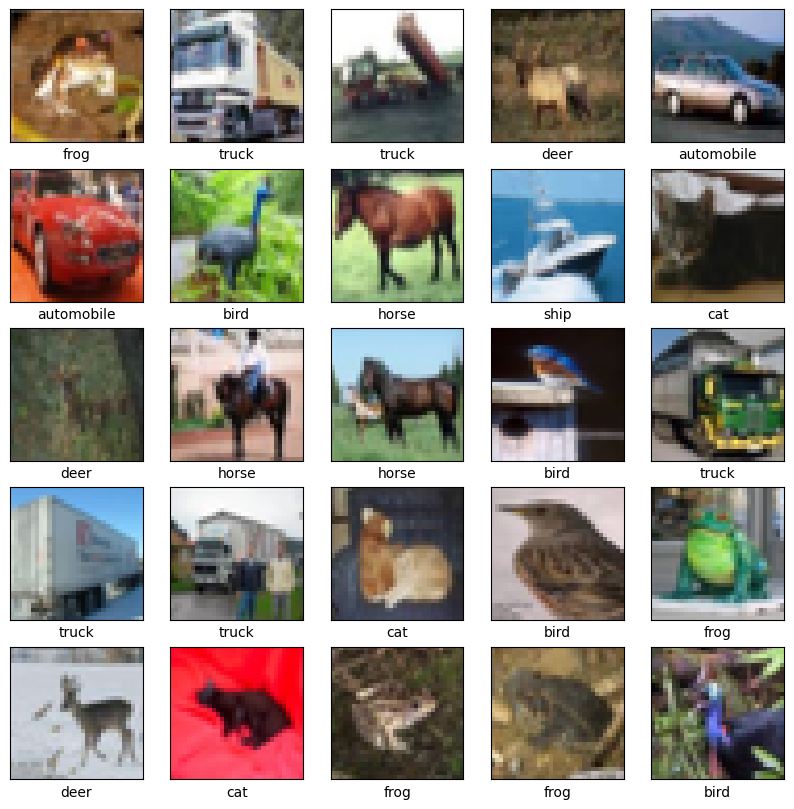

In [8]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

**Creating a CNN model**

We are going to create a CNN based classification model using *keras* module.

In [29]:
def conv_bn(x, filters):
    x = layers.SeparableConv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def res_block(x, filters):
    shortcut = x
    if x.shape[-1] != filters:                      # match channels with a 1x1 conv
        shortcut = layers.Conv2D(filters, 1, use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    y = conv_bn(x, filters)
    y = layers.SeparableConv2D(filters, 3, padding='same', use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    y = layers.Add()([shortcut, y])
    return layers.Activation('relu')(y)

def build_model():
    augment = models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(0.1, 0.1),
        # add your brightness/contrast layers here if you keep them
    ])

    inputs = layers.Input((32, 32, 3))
    x = augment(inputs)
    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = res_block(x, 32)
    x = layers.MaxPooling2D()(x); x = layers.Dropout(0.1)(x)

    x = res_block(x, 64)
    x = layers.MaxPooling2D()(x); x = layers.Dropout(0.2)(x)

    x = res_block(x, 128)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10)(x)

    m = models.Model(inputs, outputs)
    m.compile(
        optimizer=tf.keras.optimizers.AdamW(1e-3, weight_decay=5e-5),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )
    return m

model = build_model()
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5),
]

history = model.fit(
    train_images, train_labels,
    epochs=40, batch_size=64,
    validation_split=0.1,          # hold out part of TRAIN, not the test set
    callbacks=callbacks,
)

model.evaluate(test_images, test_labels)   # use the test set once, at the end

Model: "functional_705"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 32, 32, 3) │          0 │ input_layer_4[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │        864 │ sequential_4[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_24       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_20 │ (None, 32, 32,    │      1,312 │ activation_24[0]… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_25       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_21 │ (None, 32, 32,    │      1,312 │ activation_25[0]… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ activation_24[0]… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_26       │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 16, 16,    │          0 │ activation_26[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 16, 16,    │          0 │ max_pooling2d_8[… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_22 │ (None, 16, 16,    │      2,336 │ dropout_12[0][0]  │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ separable_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_27       │ (None, 16, 16,    │          0 │ batch_normalizat

 Total params: 51,018 (199.29 KB)

 Trainable params: 49,674 (194.04 KB)

 Non-trainable params: 1,344 (5.25 KB)

Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 24ms/step - accuracy: 0.3988 - loss: 1.6218 - val_accuracy: 0.4412 - val_loss: 1.5760 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.5316 - loss: 1.2988 - val_accuracy: 0.5398 - val_loss: 1.2696 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.5854 - loss: 1.1586 - val_accuracy: 0.5636 - val_loss: 1.2134 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.6180 - loss: 1.0735 - val_accuracy: 0.6250 - val_loss: 1.0383 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.6372 - loss: 1.0155 - val_accuracy: 0.6324 - val_loss: 1.0602 - learning_rate: 0.0010
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.6561 - loss: 0.9664 - val_accuracy: 0.6198 - val_loss: 1.1198 - learning_rate: 0.0010
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.6732 - l

[0.5712743401527405, 0.8008999824523926]

313/313 - 2s - 5ms/step - accuracy: 0.8009 - loss: 0.5713


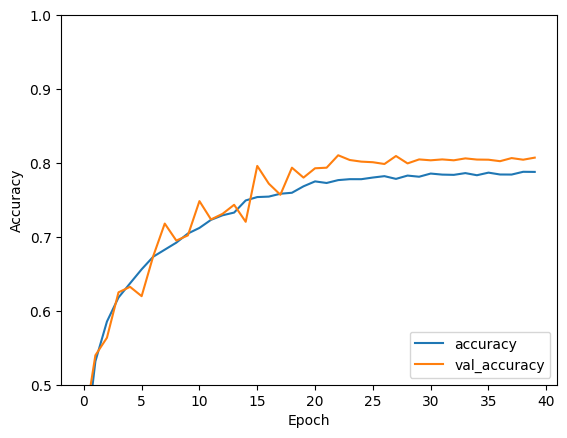

In [30]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [55]:
print(test_acc)

0.8008999824523926


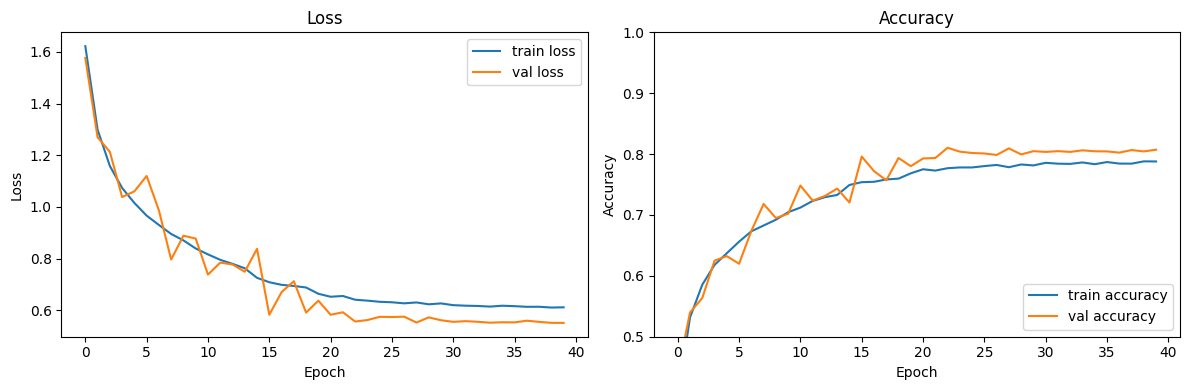

In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax1.plot(history.history['loss'], label='train loss')
ax1.plot(history.history['val_loss'], label='val loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Loss')
ax1.legend()

# Accuracy
ax2.plot(history.history['accuracy'], label='train accuracy')
ax2.plot(history.history['val_accuracy'], label='val accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy')
ax2.set_ylim([0.5, 1])
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [54]:
print(history.history['val_loss'][-1])

0.551550030708313


In [40]:
# save model
model.save('final_model.keras') #previously saved as 'final_model.h5", a legacy

In [41]:
# make a prediction for a new image.
from tensorflow.keras import preprocessing
import numpy as np

# load and prepare the image
def load_image(filename):
	# load the image
	img = preprocessing.image.load_img(filename, target_size=(32, 32))
	# convert to array
	img = preprocessing.image.img_to_array(img)
	# reshape into a single sample with 3 channels
	img = img.reshape(1, 32, 32, 3)
	# prepare pixel data
	img = img.astype('float32')
	img = img / 255.0
	return img

# load an image and predict the class
def run_example(sample):
	# load the image
	img = load_image(sample) #upload samples photos in the content folder
	# load model
	model = models.load_model('final_model.keras')
	# predict the class
	pred_list = model.predict(img)
	result = np.argmax(pred_list[0])
	print(sample,":" ,"Prediction:", class_names[result])


# run the example



run_example('cat8.webp')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step
cat8.webp : Prediction: bird


In [50]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output

def layer_summary(model):
    layer_list = model.layers
    conv = [l for l in layer_list if isinstance(l, (layers.Conv2D, layers.SeparableConv2D))]
    dense = [l for l in layer_list if isinstance(l, layers.Dense)]
    weighted = [l for l in layer_list if l.count_params() > 0]

    print(f"Total layers:           {len(layer_list)}")
    print(f"Conv layers:            {len(conv)}")
    print(f"Dense layers:           {len(dense)}")
    print(f"Layers with weights:    {len(weighted)}")
    print(f"Total parameters:       {model.count_params():,}")


layer_summary(model)
def run_example2(sample, max_layers=3, maps_per_layer=8):
    img = load_image(sample)                      # (1, 32, 32, 3) after crop/neutralise
    original = Image.open(sample).convert('RGB')

    # prediction
    probs = tf.nn.softmax(model.predict(img, verbose=0)[0]).numpy()
    result = int(np.argmax(probs))
    print(sample, ":", "Prediction:", class_names[result], f"({probs[result]:.1%})")

    # feature maps via an extractor model (works for Sequential and residual models)
    conv_layers = [l for l in model.layers
                   if isinstance(l, (layers.Conv2D, layers.SeparableConv2D))][:max_layers]
    extractor = models.Model(model.inputs, [l.output for l in conv_layers])
    acts = extractor.predict(img, verbose=0)
    if not isinstance(acts, list):                # a single output comes back as an array
        acts = [acts]

    n_rows = 1 + len(conv_layers)
    fig = plt.figure(figsize=(2 * maps_per_layer, 3 * n_rows))
    gs = fig.add_gridspec(n_rows, maps_per_layer)

    # original photo
    ax = fig.add_subplot(gs[0, :maps_per_layer // 4])
    ax.imshow(original); ax.set_title("Original"); ax.axis('off')

    # what the model sees
    ax = fig.add_subplot(gs[0, maps_per_layer // 4: maps_per_layer // 2])
    ax.imshow(img[0]); ax.set_title("Model input (32x32)"); ax.axis('off')

    # probabilities
    ax = fig.add_subplot(gs[0, maps_per_layer // 2:])
    colors = ['tab:green' if i == result else 'tab:gray' for i in range(len(probs))]
    ax.barh(class_names, probs, color=colors)
    ax.set_xlim(0, 1); ax.set_xlabel("Probability")
    ax.set_title(f"Prediction: {class_names[result]}")
    ax.invert_yaxis()

    # feature maps
    for row, (layer, act) in enumerate(zip(conv_layers, acts), start=1):
        for col in range(min(maps_per_layer, act.shape[-1])):
            ax = fig.add_subplot(gs[row, col])
            ax.imshow(act[0, :, :, col], cmap='viridis')
            ax.axis('off')
            if col == 0:
                ax.set_title(layer.name, loc='left', fontsize=9)

    plt.tight_layout()
    plt.show()
IMAGE_EXTS = ('.png', '.jpg', '.jpeg', '.webp', '.bmp', '.gif')

def list_files(folder='.', exts=IMAGE_EXTS, recursive=False):
    """Return a sorted list of file paths. Pass exts=None to list every file."""
    if recursive:
        paths = []
        for root, dirs, files in os.walk(folder):
            dirs[:] = [d for d in dirs if not d.startswith('.')]   # skip hidden folders
            paths += [os.path.join(root, f) for f in files]
    else:
        paths = [os.path.join(folder, f) for f in os.listdir(folder)
                 if os.path.isfile(os.path.join(folder, f))]
    if exts:
        paths = [p for p in paths if p.lower().endswith(tuple(exts))]
    return sorted(paths)


def file_dropdown(on_select, folder='.', exts=IMAGE_EXTS, recursive=False):
    """Show a dropdown of files; call on_select(path) when one is chosen."""
    def make_options():
        files = list_files(folder, exts, recursive)
        return [('Select a file...', None)] + [(os.path.relpath(p, folder), p) for p in files]

    dropdown = widgets.Dropdown(options=make_options(), description='File:',
                                layout=widgets.Layout(width='400px'))
    refresh = widgets.Button(description='Refresh', icon='refresh')
    out = widgets.Output()

    def on_change(change):
        if change['name'] == 'value' and change['new'] is not None:
            with out:
                clear_output(wait=True)
                on_select(change['new'])

    def on_refresh(_):
        dropdown.options = make_options()    # picks up newly uploaded files

    dropdown.observe(on_change, names='value')
    refresh.on_click(on_refresh)
    display(widgets.HBox([dropdown, refresh]), out)
    return dropdown
file_dropdown(run_example2)

Total layers:           37
Conv layers:            9
Dense layers:           1
Layers with weights:    19
Total parameters:       51,018


Output()

Dropdown(description='File:', layout=Layout(width='400px'), options=(('Select a file...', None), ('ahahaha.png…

In [ ]:
run_example2('cat8.webp')
run_example2('cat9.webp')
run_example2('cat9.jpg')
run_example2('cat10.jpg')
run_example2('plane1.jpg')
run_example2('yaeno_muteki.jpg')
run_example2('car1.jpg')
run_example2("ahahaha.png")

**Quantisation**

What quantisation does

Neural network weights are normally stored as 32-bit floats. Quantisation stores them at lower precision, usually 8-bit integers, so the file is smaller and often faster on CPUs and phones. You give up a little numerical precision in return, which usually costs only a small amount of accuracy.

In [58]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
open('model.tflite', 'wb').write(converter.convert())
print(os.path.getsize('model.tflite') / 1024, "KB")

tflite_bytes = converter.convert()
interp = tf.lite.Interpreter(model_content=tflite_bytes)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

correct = 0
for img, label in zip(test_images, test_labels.ravel()):
    interp.set_tensor(inp['index'], img[None].astype('float32'))
    interp.invoke()
    correct += int(np.argmax(interp.get_tensor(out['index'])) == label)

print(f"TFLite test accuracy: {correct / len(test_images):.4f}")

Saved artifact at '/tmp/tmpejt8vdte'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='keras_tensor_10268')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  136022605518352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605520848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605518544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605516624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605521616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605518928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605523344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605528912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605526608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605524304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136022605

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite test accuracy: 0.7992
